In [2]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
%matplotlib inline

In [4]:
df = pd.read_csv('../data/raw/cqi/df_arabica_clean.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             207 non-null    int64  
 1   ID                     207 non-null    int64  
 2   Country of Origin      207 non-null    object 
 3   Farm Name              205 non-null    object 
 4   Lot Number             206 non-null    object 
 5   Mill                   204 non-null    object 
 6   ICO Number             75 non-null     object 
 7   Company                207 non-null    object 
 8   Altitude               206 non-null    object 
 9   Region                 205 non-null    object 
 10  Producer               206 non-null    object 
 11  Number of Bags         207 non-null    int64  
 12  Bag Weight             207 non-null    object 
 13  In-Country Partner     207 non-null    object 
 14  Harvest Year           207 non-null    object 
 15  Gradin

In [6]:
df.columns

Index(['Unnamed: 0', 'ID', 'Country of Origin', 'Farm Name', 'Lot Number',
       'Mill', 'ICO Number', 'Company', 'Altitude', 'Region', 'Producer',
       'Number of Bags', 'Bag Weight', 'In-Country Partner', 'Harvest Year',
       'Grading Date', 'Owner', 'Variety', 'Status', 'Processing Method',
       'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance',
       'Uniformity', 'Clean Cup', 'Sweetness', 'Overall', 'Defects',
       'Total Cup Points', 'Moisture Percentage', 'Category One Defects',
       'Quakers', 'Color', 'Category Two Defects', 'Expiration',
       'Certification Body', 'Certification Address', 'Certification Contact'],
      dtype='object')

In [7]:
df_trunc = df[['Country of Origin', 'Altitude', 'Region', 'Harvest Year', 'Variety', 'Processing Method',
               'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Uniformity', 'Clean Cup',
               'Sweetness', 'Overall', 'Total Cup Points']]
df_trunc.head(10)

,Country of Origin,Altitude,Region,Harvest Year,Variety,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Total Cup Points
0,Colombia,1700-1930,"Piendamo,Cauca",2021 / 2022,Castillo,Double Anaerobic Washed,8.58,8.50,8.42,8.58,8.25,8.42,10.0,10.0,10.0,8.58,89.33
1,Taiwan,1200,Chiayi,2021 / 2022,Gesha,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,10.0,10.0,10.0,8.50,87.58
2,Laos,1300,Laos Borofen Plateau,2021 / 2022,Java,Semi Washed,8.33,8.42,8.08,8.17,7.92,8.17,10.0,10.0,10.0,8.33,87.42
3,Costa Rica,1900,"Los Santos,Tarrazu",2022,Gesha,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,10.0,10.0,10.0,8.25,87.17
4,Colombia,1850-2100,"Popayan,Cauca",2022,Red Bourbon,"Honey,Mossto",8.33,8.33,8.08,8.25,7.92,7.92,10.0,10.0,10.0,8.25,87.08
5,Guatemala,1668,Chimaltenango,2022,Gesha,Washed / Wet,8.33,8.33,8.25,7.83,7.83,8.17,10.0,10.0,10.0,8.25,87.00
6,Taiwan,1250,Chiayi,2021 / 2022,Gesha,Washed / Wet,8.33,8.17,8.08,8.00,7.83,8.25,10.0,10.0,10.0,8.25,86.92
7,Taiwan,1200,Chiayi,2021 / 2022,Sl34+Gesha,Natural / Dry,8.25,8.25,8.17,8.00,7.92,8.08,10.0,10.0,10.0,8.08,86.75
8,Taiwan,1250,Chiayi,2021 / 2022,SL34,Washed / Wet,8.08,8.08,8.25,8.08,7.92,8.00,10.0,10.0,10.0,8.25,86.67
9,"Tanzania, United Republic Of",1400-1700,KILIMANJARO,2022 / 2023,Bourbon,Washed / Wet,8.08,8.17,8.08,8.17,8.00,8.00,10.0,10.0,10.0,8.00,86.50


In [8]:
df_trunc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country of Origin  207 non-null    object 
 1   Altitude           206 non-null    object 
 2   Region             205 non-null    object 
 3   Harvest Year       207 non-null    object 
 4   Variety            201 non-null    object 
 5   Processing Method  202 non-null    object 
 6   Aroma              207 non-null    float64
 7   Flavor             207 non-null    float64
 8   Aftertaste         207 non-null    float64
 9   Acidity            207 non-null    float64
 10  Body               207 non-null    float64
 11  Balance            207 non-null    float64
 12  Uniformity         207 non-null    float64
 13  Clean Cup          207 non-null    float64
 14  Sweetness          207 non-null    float64
 15  Overall            207 non-null    float64
 16  Total Cup Points   207 non

In [9]:
# make sure all altitudes are in meters and get the average if the altitude is a range
nums = (df_trunc['Altitude'].astype(str)
          .str.replace(',', '', regex=False) 
          .str.findall(r'\d+\.?\d*'))
df_trunc['Altitude M'] = nums.apply(lambda x: np.mean([float(i) for i in x]) if x else np.nan)

C:\Users\nwjh2\AppData\Local\Temp\ipykernel_2900\792243649.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_trunc['Altitude M'] = nums.apply(lambda x: np.mean([float(i) for i in x]) if x else np.nan)


In [10]:
# separate into start and end for harvest years with 2 years
yrs = df_trunc['Harvest Year'].astype(str).str.findall(r'\d{4}')
df_trunc['Year Start'] = yrs.apply(lambda x: int(min(x)) if x else np.nan)
df_trunc['Year End']   = yrs.apply(lambda x: int(max(x)) if x else np.nan)

C:\Users\nwjh2\AppData\Local\Temp\ipykernel_2900\4170781470.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_trunc['Year Start'] = yrs.apply(lambda x: int(min(x)) if x else np.nan)
C:\Users\nwjh2\AppData\Local\Temp\ipykernel_2900\4170781470.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_trunc['Year End']   = yrs.apply(lambda x: int(max(x)) if x else np.nan)


In [11]:
df_trunc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country of Origin  207 non-null    object 
 1   Altitude           206 non-null    object 
 2   Region             205 non-null    object 
 3   Harvest Year       207 non-null    object 
 4   Variety            201 non-null    object 
 5   Processing Method  202 non-null    object 
 6   Aroma              207 non-null    float64
 7   Flavor             207 non-null    float64
 8   Aftertaste         207 non-null    float64
 9   Acidity            207 non-null    float64
 10  Body               207 non-null    float64
 11  Balance            207 non-null    float64
 12  Uniformity         207 non-null    float64
 13  Clean Cup          207 non-null    float64
 14  Sweetness          207 non-null    float64
 15  Overall            207 non-null    float64
 16  Total Cup Points   207 non

In [12]:
df_trunc.head(10)

,Country of Origin,Altitude,Region,Harvest Year,Variety,Processing Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean Cup,Sweetness,Overall,Total Cup Points,Altitude M,Year Start,Year End
0,Colombia,1700-1930,"Piendamo,Cauca",2021 / 2022,Castillo,Double Anaerobic Washed,8.58,8.50,8.42,8.58,8.25,8.42,10.0,10.0,10.0,8.58,89.33,1815.0,2021,2022
1,Taiwan,1200,Chiayi,2021 / 2022,Gesha,Washed / Wet,8.50,8.50,7.92,8.00,7.92,8.25,10.0,10.0,10.0,8.50,87.58,1200.0,2021,2022
2,Laos,1300,Laos Borofen Plateau,2021 / 2022,Java,Semi Washed,8.33,8.42,8.08,8.17,7.92,8.17,10.0,10.0,10.0,8.33,87.42,1300.0,2021,2022
3,Costa Rica,1900,"Los Santos,Tarrazu",2022,Gesha,Washed / Wet,8.08,8.17,8.17,8.25,8.17,8.08,10.0,10.0,10.0,8.25,87.17,1900.0,2022,2022
4,Colombia,1850-2100,"Popayan,Cauca",2022,Red Bourbon,"Honey,Mossto",8.33,8.33,8.08,8.25,7.92,7.92,10.0,10.0,10.0,8.25,87.08,1975.0,2022,2022
5,Guatemala,1668,Chimaltenango,2022,Gesha,Washed / Wet,8.33,8.33,8.25,7.83,7.83,8.17,10.0,10.0,10.0,8.25,87.00,1668.0,2022,2022
6,Taiwan,1250,Chiayi,2021 / 2022,Gesha,Washed / Wet,8.33,8.17,8.08,8.00,7.83,8.25,10.0,10.0,10.0,8.25,86.92,1250.0,2021,2022
7,Taiwan,1200,Chiayi,2021 / 2022,Sl34+Gesha,Natural / Dry,8.25,8.25,8.17,8.00,7.92,8.08,10.0,10.0,10.0,8.08,86.75,1200.0,2021,2022
8,Taiwan,1250,Chiayi,2021 / 2022,SL34,Washed / Wet,8.08,8.08,8.25,8.08,7.92,8.00,10.0,10.0,10.0,8.25,86.67,1250.0,2021,2022
9,"Tanzania, United Republic Of",1400-1700,KILIMANJARO,2022 / 2023,Bourbon,Washed / Wet,8.08,8.17,8.08,8.17,8.00,8.00,10.0,10.0,10.0,8.00,86.50,1550.0,2022,2023


<Axes: xlabel='Altitude M', ylabel='Count'>

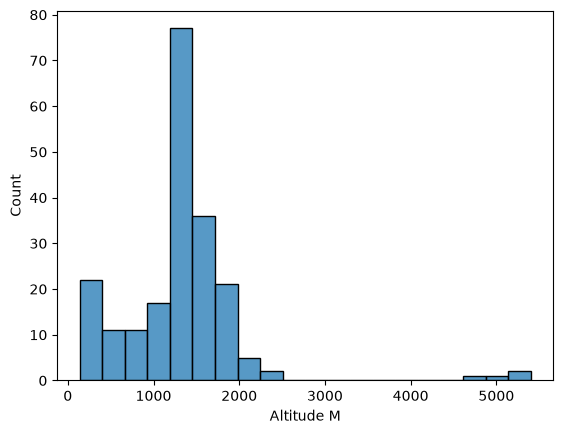

In [13]:
sns.histplot(df_trunc['Altitude M'], bins=20)

In [14]:
df_trunc.groupby('Country of Origin')['Altitude M'].mean().sort_values(ascending=False)

Country of Origin
Guatemala                       2073.238095
Vietnam                         1997.500000
Ethiopia                        1968.545455
Uganda                          1820.000000
Kenya                           1737.500000
Costa Rica                      1687.500000
Peru                            1637.500000
Colombia                        1620.277778
Tanzania, United Republic Of    1594.000000
Madagascar                      1500.000000
Honduras                        1437.692308
Myanmar                         1400.000000
Thailand                        1306.666667
El Salvador                     1285.714286
Indonesia                       1283.333333
Laos                            1283.333333
Mexico                          1272.500000
Nicaragua                       1210.714286
Panama                          1200.000000
Brazil                          1067.500000
United States (Hawaii)           848.000000
Taiwan                           729.049180
Name: Altitude

In [15]:
df_trunc.to_csv('../data/processed/cqi_clean.csv', index=False)